In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import argparse
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

RANDOM_STATE = 42
TARGET = "loan_status"


def load_data(csv_path):
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()
    df = df.drop(columns=["loan_id"], errors="ignore")
    df[TARGET] = df[TARGET].map({"Approved": 1, "Rejected": 0})
    return df


def build_preprocessor(df, target=TARGET):
    features = df.drop(columns=[target])
    numeric_cols = features.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = features.select_dtypes(exclude=[np.number]).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])
    return preprocessor, numeric_cols, categorical_cols


def get_models():
    return {
        "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
        "Naive Bayes": GaussianNB(),
        "KNN": KNeighborsClassifier(n_neighbors=15),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    }


def evaluate_all(df, target=TARGET):
    X = df.drop(columns=[target])
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
    )

    preprocessor, num_cols, cat_cols = build_preprocessor(df, target)
    models = get_models()

    results = []
    fitted_pipelines = {}

    for name, model in models.items():
        pipe = Pipeline([
            ("prep", preprocessor),
            ("clf", model),
        ])
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe.named_steps["clf"], "predict_proba") else None

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan,
        })

        print(f"\n{'='*55}\n{name}\n{'='*55}")
        print(classification_report(y_test, y_pred, target_names=["Rejected", "Approved"]))

        fitted_pipelines[name] = (pipe, y_test, y_pred)

    results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
    return results_df, fitted_pipelines, X_test, y_test


def plot_comparison(results_df, fitted_pipelines, out_dir="."):
    metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
    fig, ax = plt.subplots(figsize=(10, 6))
    results_df.set_index("Model")[metrics].plot(kind="bar", ax=ax)
    ax.set_title("Model Performance Comparison — Loan Approval Prediction")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend(loc="lower right")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f"{out_dir}/model_comparison.png", dpi=150)
    plt.close()

    n = len(fitted_pipelines)
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 4))
    for ax, (name, (pipe, y_test, y_pred)) in zip(axes, fitted_pipelines.items()):
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"{out_dir}/confusion_matrices.png", dpi=150)
    plt.close()


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--csv", type=str, default="loan_approval_dataset.csv")
    args, _ = parser.parse_known_args()

    if not os.path.isfile(args.csv):
        print(f"Could not find '{args.csv}' in {os.getcwd()}.")
        print("Upload it first, e.g. in Colab:")
        print("    from google.colab import files")
        print("    files.upload()")
        print("or pass its full path with --csv /path/to/file.csv")
        sys.exit(1)

    df = load_data(args.csv)
    print(f"Dataset shape: {df.shape}")
    print(f"Class balance:\n{df[TARGET].value_counts(normalize=True).round(3)}")

    results_df, fitted_pipelines, X_test, y_test = evaluate_all(df)

    print("\n" + "=" * 55)
    print("MODEL COMPARISON SUMMARY")
    print("=" * 55)
    print(results_df.to_string(index=False))

    results_df.to_csv("model_comparison_results.csv", index=False)
    plot_comparison(results_df, fitted_pipelines)

    best_model = results_df.iloc[0]["Model"]
    print(f"\nBest performing model (by F1-Score): {best_model}")

Dataset shape: (4269, 12)
Class balance:
loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64

Decision Tree
              precision    recall  f1-score   support

    Rejected       0.99      0.93      0.96       404
    Approved       0.96      0.99      0.98       664

    accuracy                           0.97      1068
   macro avg       0.97      0.96      0.97      1068
weighted avg       0.97      0.97      0.97      1068


Naive Bayes
              precision    recall  f1-score   support

    Rejected       0.92      0.94      0.93       404
    Approved       0.96      0.95      0.96       664

    accuracy                           0.95      1068
   macro avg       0.94      0.95      0.94      1068
weighted avg       0.95      0.95      0.95      1068


KNN
              precision    recall  f1-score   support

    Rejected       0.86      0.89      0.88       404
    Approved       0.93      0.91      0.92       664

    accuracy                           0.

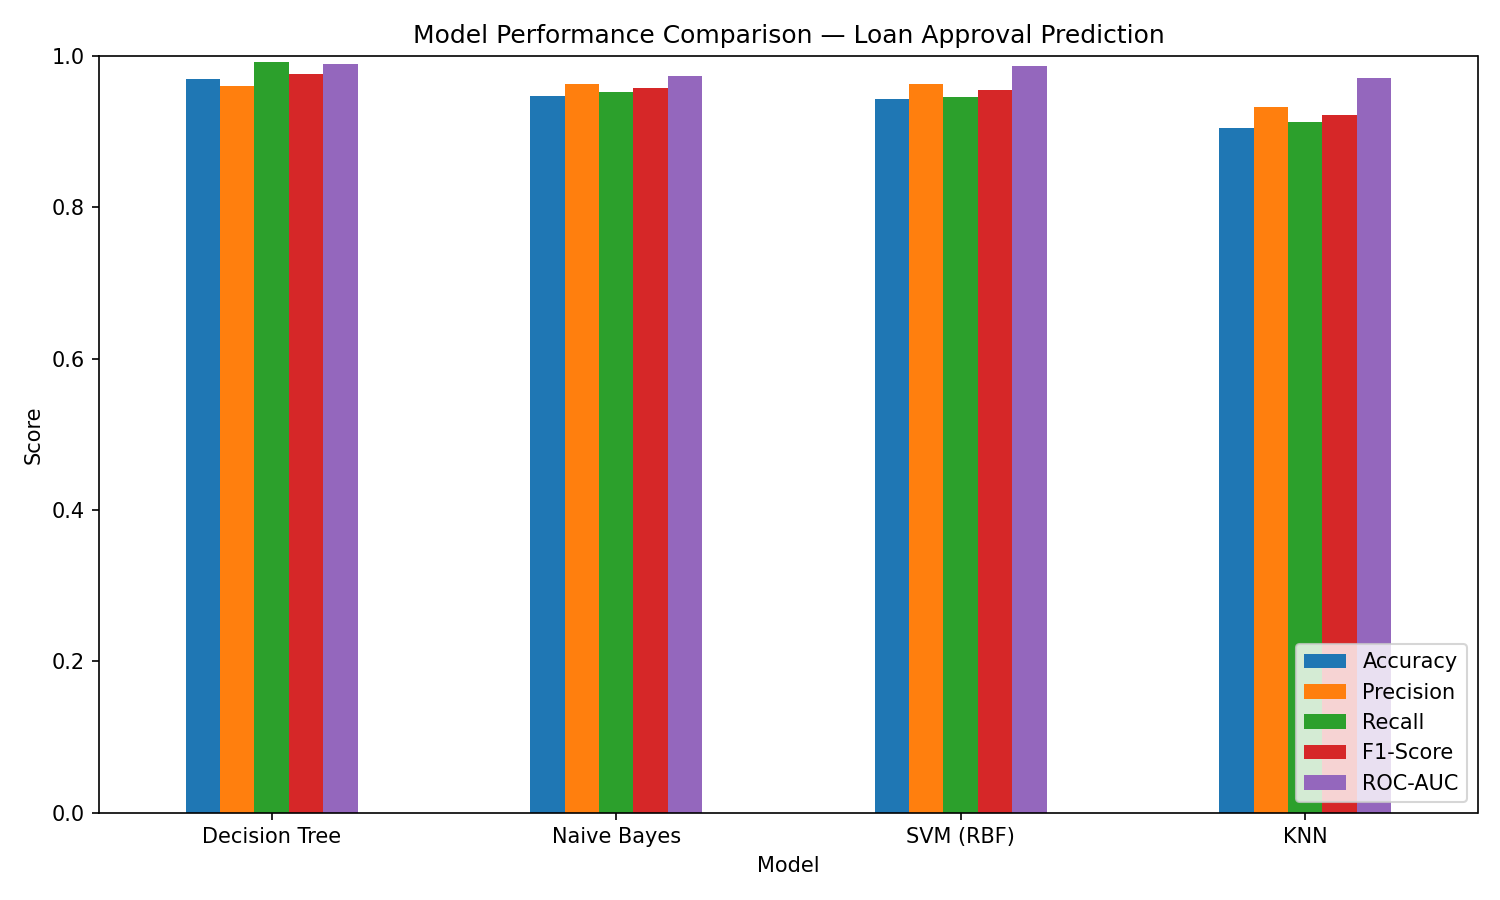

In [ ]:
from IPython.display import Image, display

display(Image("model_comparison.png"))


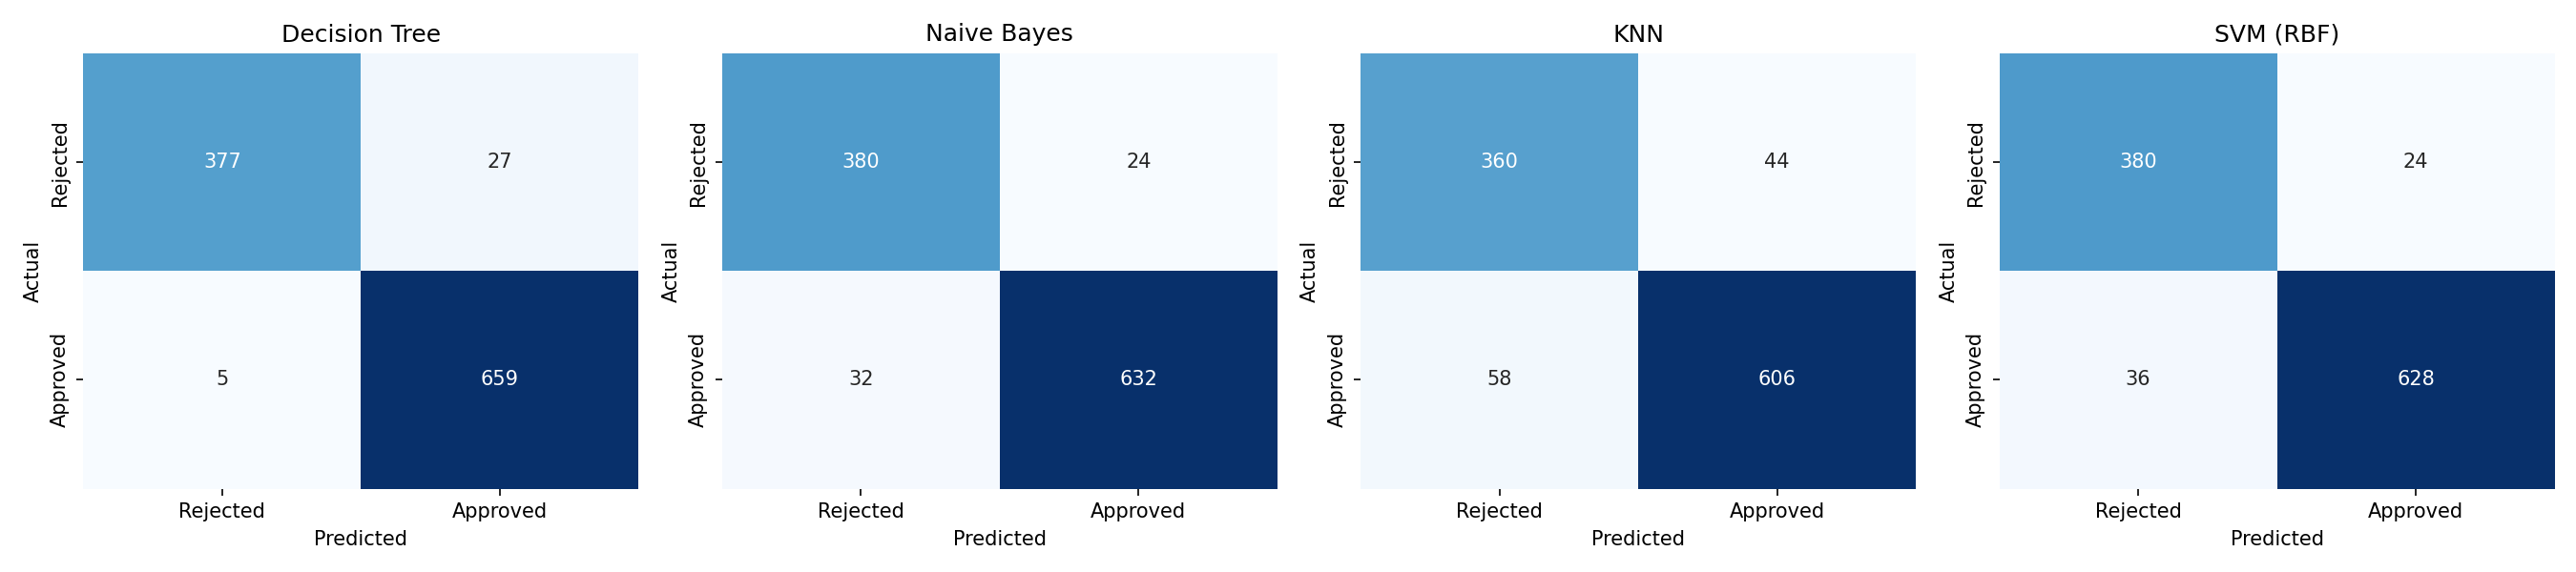

In [ ]:
from IPython.display import Image, display
display(Image("confusion_matrices.png"))

In [2]:
import os
csv_name = [f for f in os.listdir(".") if f.endswith(".csv")][0]
print(csv_name)

df = load_data(csv_name)
results_df, fitted_pipelines, X_test, y_test = evaluate_all(df)
results_df.to_csv("model_comparison_results.csv", index=False)
plot_comparison(results_df, fitted_pipelines)

results_df

IndexError: list index out of range